# Behavior for increasing n:

In [1]:
import numpy as np
import random
import pandas as pd

In [2]:
# Hyperparameters we selected

Episodic_M_grid = [(1e-06, 0.01, 0.9, 0.2)]
Continuing_UM_grid = [(1e-06, 0.0005, 0.8, 0.2)]
Average_Reward_UM_grid = [(1e-06, 0.001, 0.0001, 0.2)]
Average_Reward_M_grid = [(1e-06, 0.005, 0.0005, 0.2)]

seed = 272
random.seed(seed)
np.random.seed(seed)
seeds = np.random.choice(100000, size=100, replace=False).tolist()

Ns = [int(k*(k-1)/2) for k in range(5, 26)]
max_it = 50000

In [3]:
print(*Ns)

10 15 21 28 36 45 55 66 78 91 105 120 136 153 171 190 210 231 253 276 300


In [5]:
Names = ["Episodic_M_R",
        "Continuing_UM_R",
        "Average_reward_UM_R",
        "Average_reward_M_R"]

N = { "Episodic_M_R" : 0,
      "Continuing_UM_R" : 1,
      "Average_reward_UM_R" : 2,
      "Average_reward_M_R" : 3
    }

MS = []

for name in Names:
  path = name + ".csv"
  A = pd.read_csv(path)
  MS.append(A[['n','seed', 'a_d', 'r_d', 'w_b','n_it']])

In [6]:
GS_seed_average = []

for i in range(len(Names)):
    df = MS[i]
    a = [(0.0, 0.0, 0.0, 0.0) for n in Ns]
    A = pd.DataFrame(a,
                   index = list(Ns),
                   columns=['a_d', 'r_d', 'w_b', 'n_it'])

    for n in Ns:
      avg_a_d = np.mean(df.loc[(df['n'] == n), ['a_d']])
      avg_r_d = np.mean(df.loc[(df['n'] == n), ['r_d']])
      avg_w_b = np.mean(df.loc[(df['n'] == n), ['w_b']])
      avg_n_it = np.mean(df.loc[(df['n'] == n), ['n_it']])
      A.at[n, 'a_d'] = avg_a_d
      A.at[n, 'r_d'] = avg_r_d
      A.at[n, 'w_b'] = avg_w_b/n
      A.at[n, 'n_it'] = avg_n_it

    GS_seed_average.append(A)

In [7]:
for name in Names:
  df = GS_seed_average[N[name]][['r_d', 'w_b', 'n_it']]
  print("--Results for "+name+"--\n")
  print(df)
  print("\n\n")

--Results for Episodic_M_R--

          r_d       w_b     n_it
10   0.011624  0.020000  50000.0
15   0.001888  0.017333  50000.0
21   0.002619  0.020952  50000.0
28   0.002755  0.023214  50000.0
36   0.003154  0.024167  50000.0
45   0.005316  0.033111  50000.0
55   0.011418  0.047455  50000.0
66   0.024450  0.069697  50000.0
78   0.062900  0.112564  50000.0
91   0.109153  0.144396  50000.0
105  0.172877  0.184952  50000.0
120  0.238479  0.218083  50000.0
136  0.303463  0.246985  50000.0
153  0.377562  0.279477  50000.0
171  0.426229  0.300058  50000.0
190  0.480315  0.322211  50000.0
210  0.517661  0.342571  50000.0
231  0.560315  0.359221  50000.0
253  0.585354  0.368972  50000.0
276  0.619686  0.379783  50000.0
300  0.631872  0.384533  50000.0



--Results for Continuing_UM_R--

          r_d       w_b      n_it
10   0.042521  0.053000  35348.89
15   0.019273  0.038000  32402.49
21   0.003879  0.019048  30763.49
28   0.001728  0.014643  36226.63
36   0.002113  0.017222  36613.66
45  

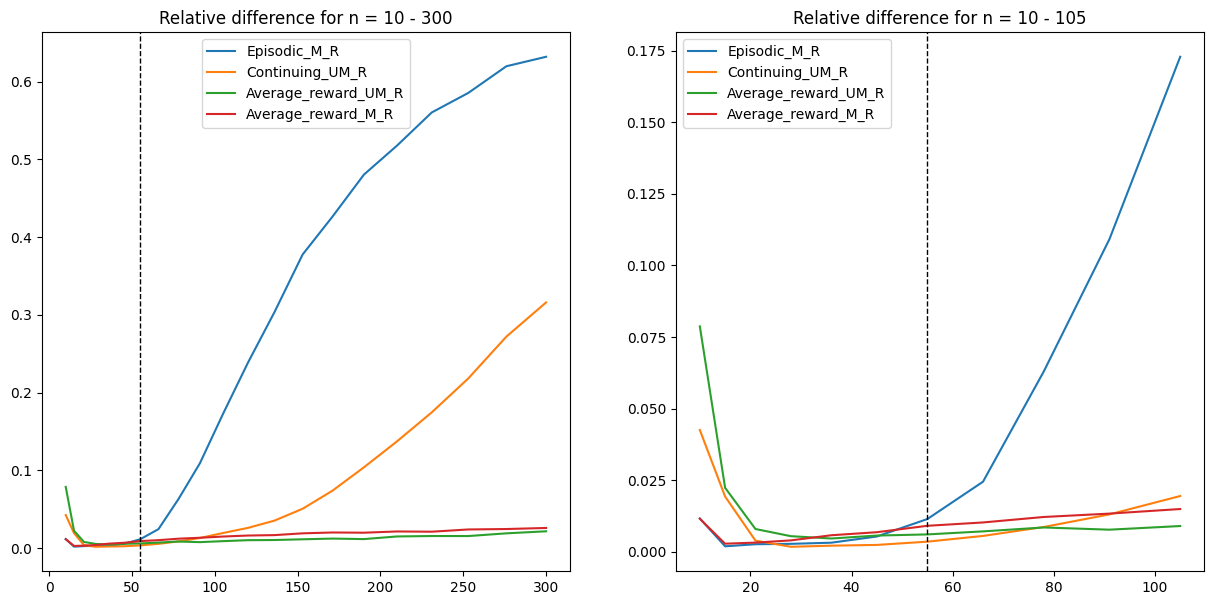

In [8]:
import matplotlib.pyplot as plt


plt.rcParams["figure.figsize"] = (15,7)

plt.subplot(1, 2, 1)
plt.title("Relative difference for n = 10 - 300")
for name in Names:
  df = GS_seed_average[N[name]]['r_d']
  plt.plot(df, label = name)
plt.axvline(55, color='k', linestyle='dashed', linewidth=1)
plt.legend()

plt.subplot(1, 2, 2)
plt.title("Relative difference for n = 10 - 105")
for name in Names:
  df = GS_seed_average[N[name]]['r_d']
  plt.plot(df.loc[Ns[0:11]], label = name)
plt.axvline(55, color='k', linestyle='dashed', linewidth=1)
plt.legend()